# Inspect raw and processed UA-DETRAC data locally or on Colab.



In [3]:
from pathlib import Path
import os
import subprocess
import sys
import json

# Colab mounts Drive; local runs discover the repo from the notebook directory.
try:
    from google.colab import drive
    IN_COLAB = True
    drive.mount('/content/drive')
except ImportError:
    IN_COLAB = False

project_override = os.environ.get('UA_DETRAC_PROJECT')
candidates = [Path.cwd(), *Path.cwd().parents]
if project_override:
    candidates.insert(0, Path(project_override))
if IN_COLAB and not project_override:
    candidates.insert(0, Path('/content/drive/MyDrive/CS331/CS331-Vehicle-Tracking'))
ROOT_PATH = next(
    (path for path in candidates if (path / 'scripts/prepare_dataset.py').is_file()),
    None,
)
if ROOT_PATH is None:
    raise FileNotFoundError('Open this notebook from inside the project repository.')

sys.path.insert(0, str(ROOT_PATH))
subprocess.run(
    [sys.executable, '-m', 'pip', 'install', '-q', '-r',
     str(ROOT_PATH / 'requirements.txt')],
    check=True,
)
LOCAL_RAW_PATH = Path(os.environ.get('UA_DETRAC_RAW', ROOT_PATH / 'data/raw'))
if IN_COLAB and 'UA_DETRAC_RAW' not in os.environ:
    downloaded_raw = Path('/content/ua_detrac/raw')
    if downloaded_raw.is_dir():
        LOCAL_RAW_PATH = downloaded_raw
DATA_RAW_PATH = LOCAL_RAW_PATH
WORK_ROOT = Path('/content/ua_detrac') if IN_COLAB else ROOT_PATH / 'outputs/ua_detrac'
WORK_ROOT.mkdir(parents=True, exist_ok=True)
DATASET = Path(os.environ.get('UA_DETRAC_OUTPUT', WORK_ROOT / 'dataset_v1.1'))
INVENTORY_PATH = WORK_ROOT / 'raw_inventory.json'
import pandas as pd
import matplotlib.pyplot as plt

print('Project:', ROOT_PATH)
print('Raw:', DATA_RAW_PATH)
print('Dataset output:', DATASET)








Project: d:\ZB\Code\UIT\CS331\CS331-Vehicle-Tracking
Raw: d:\ZB\Code\UIT\CS331\CS331-Vehicle-Tracking\data\raw
Dataset output: d:\ZB\Code\UIT\CS331\CS331-Vehicle-Tracking\outputs\ua_detrac\dataset_v1.1


## Raw inventory: file integrity and annotation coverage. XML frame omissions are reported as coverage, not automatically as download errors.



In [2]:
result = subprocess.run(
    [sys.executable, str(ROOT_PATH / 'scripts/inspect_dataset.py'),
     '--raw', str(DATA_RAW_PATH), '--report', str(INVENTORY_PATH)],
    capture_output=True,
    text=True,
)
print(result.stdout)
print(result.stderr)
if result.returncode:
    raise RuntimeError('Raw inventory failed; see the traceback above.')

inventory = json.loads(INVENTORY_PATH.read_text(encoding='utf-8'))
rows = pd.DataFrame(inventory['sequences'])
display(rows[[
    'sequence', 'expected', 'ready', 'num_images', 'num_annotation_frames',
    'num_unannotated_images', 'annotation_coverage', 'issues',
]])
display(rows.loc[~rows.ready | ~rows.expected])



{
  "raw": "D:\\ZB\\Code\\UIT\\CS331\\CS331-Vehicle-Tracking\\data\\raw",
  "expected_sequences": 100,
  "sequences_with_images": 100,
  "sequences_with_xml": 100,
  "incomplete_sequences_with_images": [],
  "partial_annotation_sequences": [
    "MVI_39051",
    "MVI_39211",
    "MVI_39271",
    "MVI_39761",
    "MVI_39781",
    "MVI_39811",
    "MVI_39851",
    "MVI_39931",
    "MVI_40152",
    "MVI_40162",
    "MVI_40211",
    "MVI_40213",
    "MVI_40743",
    "MVI_40763",
    "MVI_40793",
    "MVI_40991",
    "MVI_40992",
    "MVI_63544"
  ],
  "invalid_sequences": [],
  "unannotated_image_frames": 1879,
  "ready_sequences": 100,
  "missing_images": [],
  "missing_xml": [],
  "unexpected_sequences": []
}
Detailed inventory saved to D:\ZB\Code\UIT\CS331\CS331-Vehicle-Tracking\outputs\ua_detrac\raw_inventory.json




,sequence,expected,ready,num_images,num_annotation_frames,num_unannotated_images,annotation_coverage,issues
0,MVI_20011,True,True,664,664,0,1.0,[]
1,MVI_20012,True,True,936,936,0,1.0,[]
2,MVI_20032,True,True,437,437,0,1.0,[]
3,MVI_20033,True,True,784,784,0,1.0,[]
4,MVI_20034,True,True,800,800,0,1.0,[]
...,...,...,...,...,...,...,...,...
95,MVI_63553,True,True,1405,1405,0,1.0,[]
96,MVI_63554,True,True,1445,1445,0,1.0,[]
97,MVI_63561,True,True,1285,1285,0,1.0,[]
98,MVI_63562,True,True,1185,1185,0,1.0,[]


,sequence,expected,ready,xml_paths,image_directories,num_images,num_annotation_frames,num_unannotated_images,annotation_coverage,missing_image_frames,unannotated_image_frames,extra_image_frames,issues


In [3]:
from src.data.split import load_splits

fixed_splits = load_splits(ROOT_PATH / 'splits')
usable = set(rows.loc[rows.ready & rows.expected, 'sequence'])
for part, names in fixed_splits.items():
    available = [sequence for sequence in names if sequence in usable]
    print(f'{part}: {len(available)}/{len(names)} structurally usable')
    print('Partial annotation:', [
        sequence for sequence in available
        if int(rows.loc[rows.sequence == sequence, 'num_unannotated_images'].iloc[0]) > 0
    ])



train: 48/48 structurally usable
Partial annotation: ['MVI_39761', 'MVI_39851', 'MVI_39931', 'MVI_40152', 'MVI_40162', 'MVI_40211', 'MVI_40213', 'MVI_40992', 'MVI_63544']
val: 12/12 structurally usable
Partial annotation: ['MVI_39781', 'MVI_39811', 'MVI_40991']
test: 40/40 structurally usable
Partial annotation: ['MVI_39051', 'MVI_39211', 'MVI_39271', 'MVI_40743', 'MVI_40763', 'MVI_40793']


## Optional: inspect processed dataset
The remaining cells run only if DATASET exists and has been prepared successfully. Run 00b after inspecting raw. Unknown occlusion/truncation ratios remain NaN; plots include empty frames in objects/frame.



In [ ]:
if (DATASET / 'metadata/manifest.json').is_file():
    a = pd.read_csv(DATASET / 'canonical/annotations.csv')
    s = pd.read_csv(DATASET / 'metadata/sequences.csv')
    display(s)
    display(pd.read_csv(DATASET / 'metadata/dataset_stats.csv'))
    display(json.loads((DATASET / 'metadata/validation_report.json').read_text()))
    display(s.groupby(['width', 'height', 'fps'], dropna=False).size())
else:
    print('Processed dataset is not ready; review raw inventory first.')



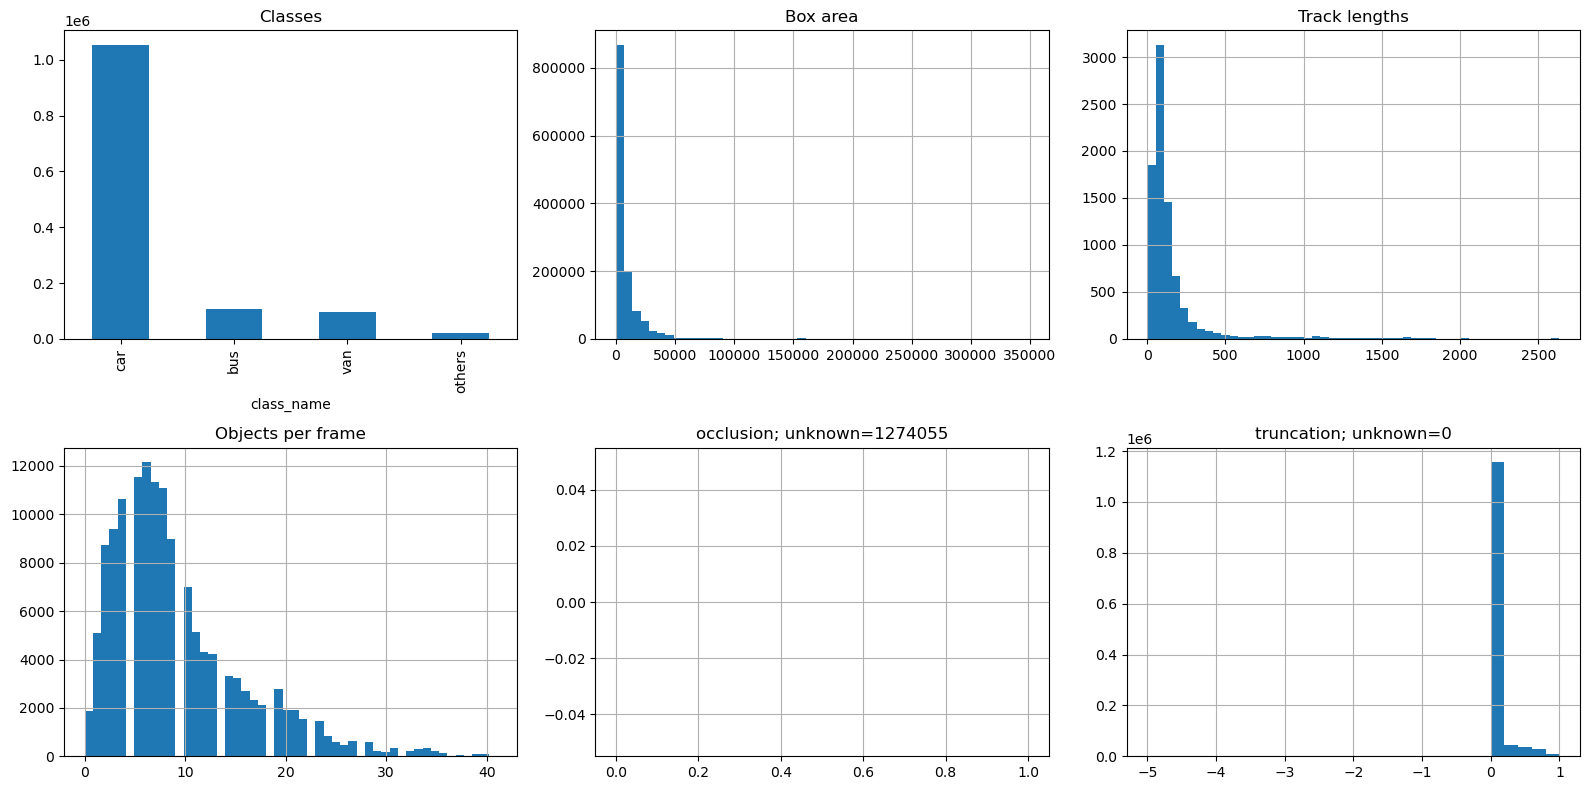

In [5]:
if (DATASET / 'metadata/manifest.json').is_file():
    fig, axes = plt.subplots(2, 3, figsize=(16, 8))
    a.class_name.value_counts().plot.bar(ax=axes[0,0], title='Classes')
    (a.w * a.h).hist(bins=50, ax=axes[0,1]); axes[0,1].set_title('Box area')
    a.groupby(['sequence','track_id']).size().hist(bins=50, ax=axes[0,2]); axes[0,2].set_title('Track lengths')
    counts = a.groupby(['sequence', 'frame_id']).size()
    index = pd.MultiIndex.from_tuples([(r.sequence, f) for r in s.itertuples() for f in range(1, r.num_frames+1)])
    counts.reindex(index, fill_value=0).hist(bins=50, ax=axes[1,0]); axes[1,0].set_title('Objects per frame')
    for field, ax in zip(['occlusion', 'truncation'], axes[1,1:]):
        a[field].dropna().hist(bins=30, ax=ax)
        ax.set_title(f'{field}; unknown={a[field].isna().sum()}')
    plt.tight_layout()
else:
    print('Processed dataset is not ready; review raw inventory first.')

